# Week 2, Thursday: Feature Selection vs Dimensionality Reduction + Full Comparison
Two parts:
1. **Feature selection vs PCA** on Wine.
2. **The checkpoint:** one pipeline with preprocessing + 3 classifiers (Decision Tree, kNN, Naive Bayes), run on Titanic, Wine and Breast Cancer, with confusion matrices and a metrics table.


## 0. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
sns.set_theme(style='whitegrid')
np.random.seed(42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
wine = load_wine(as_frame=True); cancer = load_breast_cancer(as_frame=True)

# Part A: Feature selection vs Dimensionality reduction
- **Feature selection** keeps a **subset of the original features** and throws the rest away. The kept features stay interpretable ("alcohol", "proline").
- **Dimensionality reduction (PCA)** builds **new features** that are combinations of all the originals, ordered by how much variation they capture. They are compact but harder to interpret ("component 1" is a blend of many chemicals).

## A1. Feature selection with SelectKBest (Wine)

Top 5 selected features: ['alcohol', 'flavanoids', 'color_intensity', 'od280/od315_of_diluted_wines', 'proline']


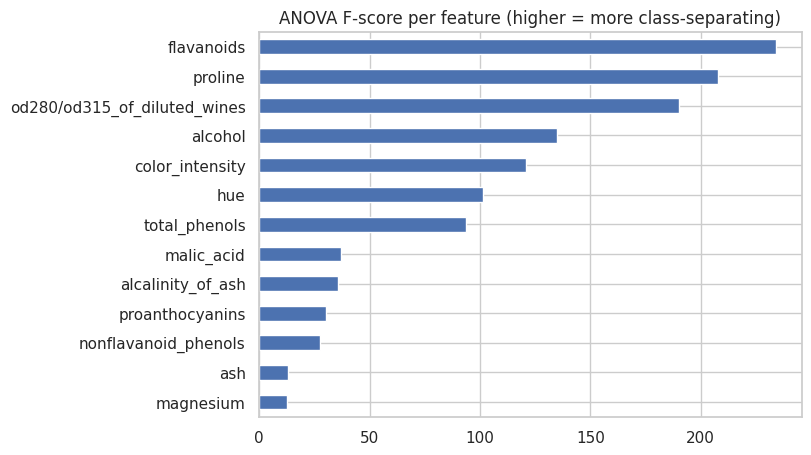

In [2]:
# Scale is not needed for the ANOVA F-score, but we keep the habit of fitting on the full data only for EXPLORING.
sel = SelectKBest(score_func=f_classif, k=5).fit(wine.data, wine.target)
scores = pd.Series(sel.scores_, index=wine.feature_names).sort_values(ascending=False)
print('Top 5 selected features:', list(wine.data.columns[sel.get_support()]))
scores.plot.barh(figsize=(7, 5), title='ANOVA F-score per feature (higher = more class-separating)').invert_yaxis(); plt.show()

## A2. Dimensionality reduction with PCA (Wine)

Variance explained by first 2 components: [0.362 0.192] -> total 0.554
First 5 components cumulative: [0.362 0.554 0.665 0.736 0.802]


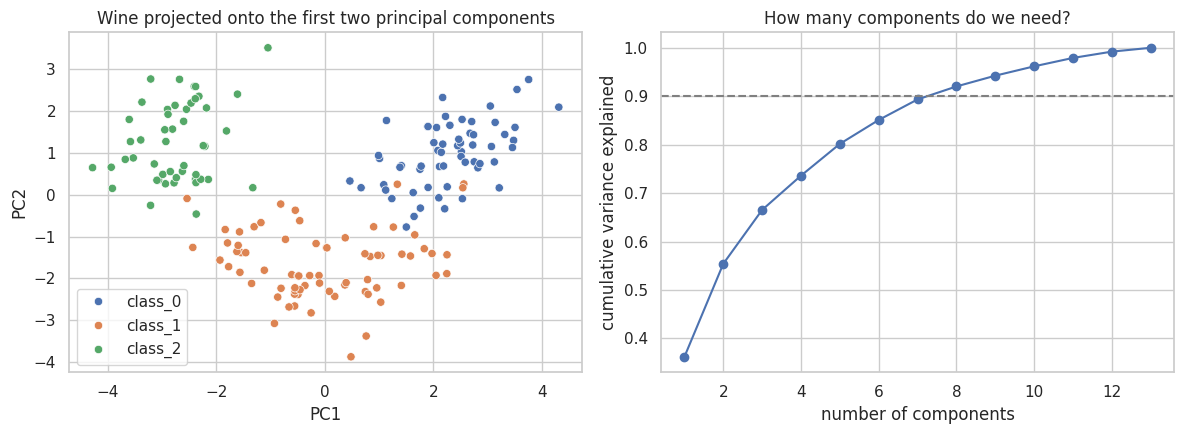

In [3]:
# PCA is distance/variance based, so SCALE FIRST
Xs = StandardScaler().fit_transform(wine.data)
pca = PCA().fit(Xs)
evr = pca.explained_variance_ratio_
print('Variance explained by first 2 components:', np.round(evr[:2], 3), '-> total', round(evr[:2].sum(), 3))
print('First 5 components cumulative:', np.round(np.cumsum(evr)[:5], 3))

Z = PCA(n_components=2).fit_transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=wine.target_names[wine.target], ax=ax[0])
ax[0].set(xlabel='PC1', ylabel='PC2', title='Wine projected onto the first two principal components')
ax[1].plot(range(1, len(evr) + 1), np.cumsum(evr), 'o-'); ax[1].axhline(0.9, ls='--', c='gray')
ax[1].set(xlabel='number of components', ylabel='cumulative variance explained', title='How many components do we need?')
plt.tight_layout(); plt.show()

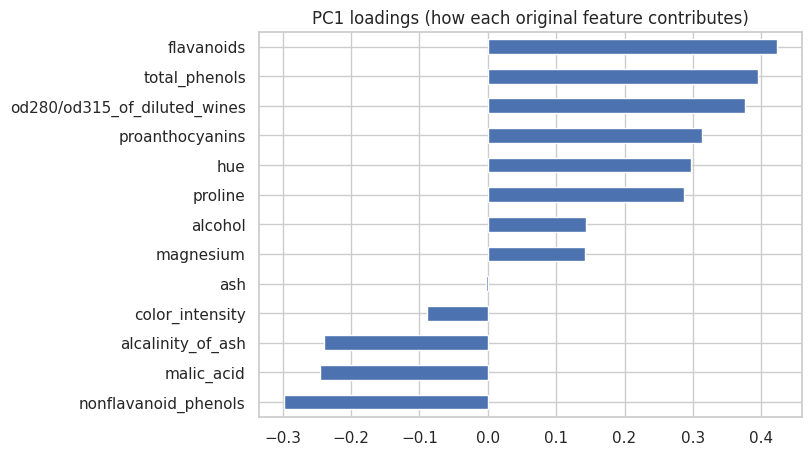

In [4]:
# Which original features drive PC1?
loadings = pd.Series(pca.components_[0], index=wine.feature_names).sort_values()
loadings.plot.barh(figsize=(7, 5), title='PC1 loadings (how each original feature contributes)'); plt.show()

## A3. Does it hurt accuracy? Try both inside a pipeline

In [5]:
def cvm(model): return cross_val_score(model, wine.data, wine.target, cv=cv).mean()
knn = KNeighborsClassifier(5)
print('kNN on all 13 features            :', round(cvm(make_pipeline(StandardScaler(), knn)), 3))
print('kNN + SelectKBest(k=5)            :', round(cvm(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=5), KNeighborsClassifier(5))), 3))
print('kNN + PCA(2 components)           :', round(cvm(make_pipeline(StandardScaler(), PCA(2), KNeighborsClassifier(5))), 3))
print('kNN + PCA(5 components)           :', round(cvm(make_pipeline(StandardScaler(), PCA(5), KNeighborsClassifier(5))), 3))

kNN on all 13 features            : 0.972
kNN + SelectKBest(k=5)            : 0.955
kNN + PCA(2 components)           : 0.967
kNN + PCA(5 components)           : 0.972


**Why the selector and PCA are inside the pipeline:** they learn from data (scores, directions), so they must be fitted on each training fold only, otherwise the test fold leaks in, exactly like scaling.



# Part B: The checkpoint: preprocessing + 3 classifiers, 3 datasets
One function builds the right pipeline for any dataset: it **imputes, encodes and scales** whatever the dataset needs, then applies one of the three classifiers.

In [6]:
# ---- Load the 3 datasets into (X, y) with their column types ----
titanic = sns.load_dataset('titanic')
t_num, t_cat = ['age', 'fare', 'sibsp', 'parch', 'pclass'], ['sex', 'embarked']
datasets = {
    'Titanic':       (titanic[t_num + t_cat], titanic['survived'], t_num, t_cat, ['died', 'survived']),
    'Wine':          (wine.data, wine.target, list(wine.data.columns), [], list(wine.target_names)),
    'Breast Cancer': (cancer.data, cancer.target, list(cancer.data.columns), [], list(cancer.target_names)),
}

def make_preprocessor(num_cols, cat_cols):
    steps = [('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                       ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols))
    return ColumnTransformer(steps)

def make_models(num_cols, cat_cols):
    clfs = {'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
            'kNN (k=5)': KNeighborsClassifier(n_neighbors=5),
            'Naive Bayes': GaussianNB()}
    return {n: Pipeline([('prep', make_preprocessor(num_cols, cat_cols)), ('model', c)]) for n, c in clfs.items()}

# ---- One function: cross-validated scores for all three classifiers on one dataset ----
def compare(name):
    X, y, num_cols, cat_cols, _ = datasets[name]
    out = {}
    for mname, pipe in make_models(num_cols, cat_cols).items():
        s = cross_val_score(pipe, X, y, cv=cv)
        out[mname] = (s.mean(), s.std())
    return out

cv_table = pd.DataFrame({d: {m: f'{v[0]:.3f} ± {v[1]:.3f}' for m, v in compare(d).items()} for d in datasets})
cv_table

,Titanic,Wine,Breast Cancer
Decision Tree,0.818 ± 0.016,0.888 ± 0.031,0.923 ± 0.030
kNN (k=5),0.813 ± 0.018,0.972 ± 0.018,0.963 ± 0.018
Naive Bayes,0.787 ± 0.017,0.977 ± 0.028,0.930 ± 0.020


## B2. Confusion matrices (train/test split, 3 models side by side)

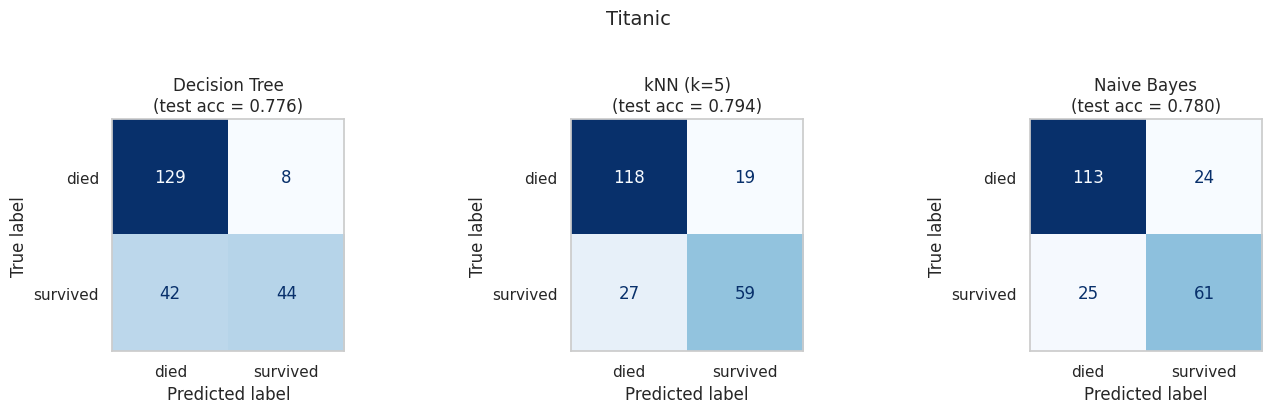

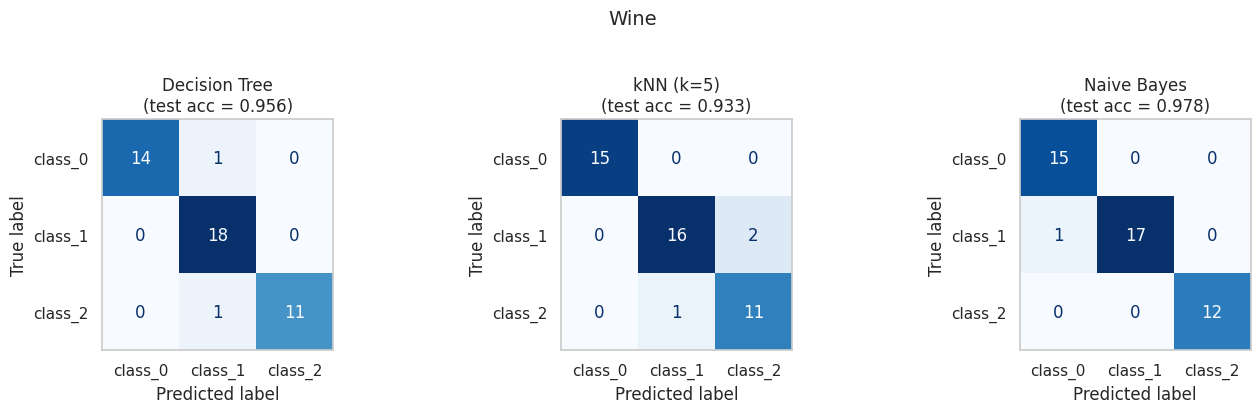

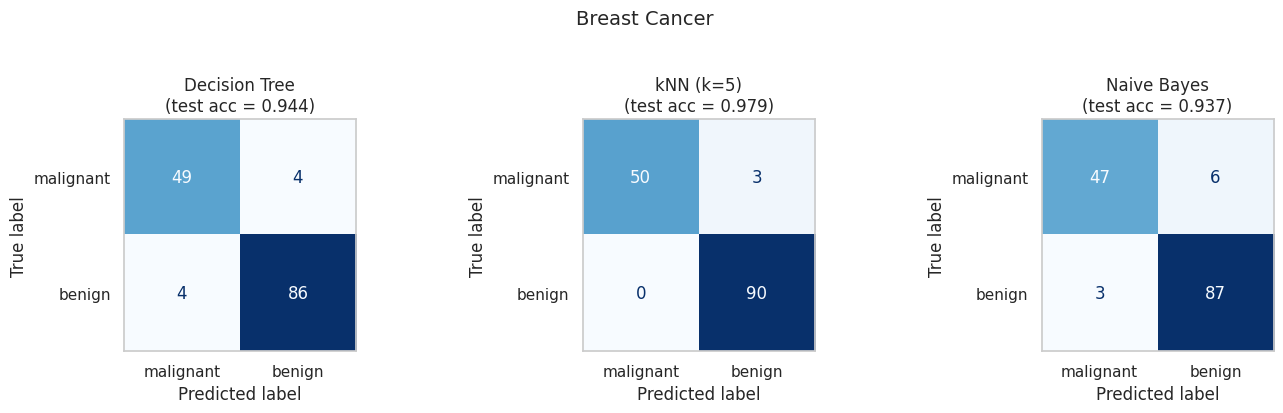

In [7]:
def plot_confusions(name):
    X, y, num_cols, cat_cols, labels = datasets[name]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (mname, pipe) in zip(axes, make_models(num_cols, cat_cols).items()):
        pipe.fit(Xtr, ytr)
        ConfusionMatrixDisplay.from_predictions(yte, pipe.predict(Xte), display_labels=labels, cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(f'{mname}\n(test acc = {pipe.score(Xte, yte):.3f})'); ax.grid(False)
    fig.suptitle(name, fontsize=14, y=1.03); plt.tight_layout(); plt.show()

for d in datasets: plot_confusions(d)

**How to read a confusion matrix:** rows = the **true** class, columns = what the model **predicted**. The diagonal holds correct predictions, and every off-diagonal cell is a mistake of a specific kind.


## B3. One metrics table and bar chart (accuracy, precision, recall, F1)

In [8]:
rows = []
for dname, (X, y, num_cols, cat_cols, labels) in datasets.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    for mname, pipe in make_models(num_cols, cat_cols).items():
        pred = pipe.fit(Xtr, ytr).predict(Xte)
        avg = 'binary' if len(np.unique(y)) == 2 else 'macro'
        # for Breast Cancer the 'positive' class we care about is malignant (0)
        pl = 0 if dname == 'Breast Cancer' else 1
        kw = dict(average=avg, zero_division=0) if avg == 'macro' else dict(average='binary', pos_label=pl, zero_division=0)
        rows.append(dict(dataset=dname, model=mname, accuracy=accuracy_score(yte, pred),
                         precision=precision_score(yte, pred, **kw), recall=recall_score(yte, pred, **kw), f1=f1_score(yte, pred, **kw)))
results = pd.DataFrame(rows).round(3)
display(results)
print('Note: Titanic positive class = survived; Breast Cancer positive class = malignant; Wine = macro average over 3 classes.')

,dataset,model,accuracy,precision,recall,f1
0,Titanic,Decision Tree,0.776,0.846,0.512,0.638
1,Titanic,kNN (k=5),0.794,0.756,0.686,0.720
2,Titanic,Naive Bayes,0.780,0.718,0.709,0.713
3,Wine,Decision Tree,0.956,0.967,0.950,0.956
4,Wine,kNN (k=5),0.933,0.929,0.935,0.931
5,Wine,Naive Bayes,0.978,0.979,0.981,0.980
6,Breast Cancer,Decision Tree,0.944,0.925,0.925,0.925
7,Breast Cancer,kNN (k=5),0.979,1.000,0.943,0.971
8,Breast Cancer,Naive Bayes,0.937,0.940,0.887,0.913


Note: Titanic positive class = survived; Breast Cancer positive class = malignant; Wine = macro average over 3 classes.


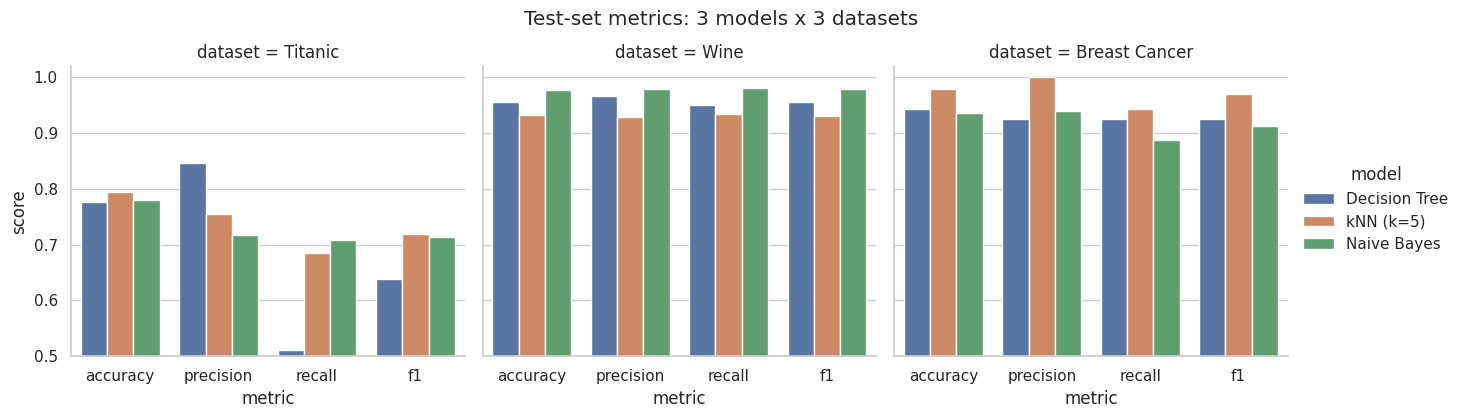

In [9]:
melted = results.melt(id_vars=['dataset', 'model'], var_name='metric', value_name='score')
g = sns.catplot(data=melted, x='metric', y='score', hue='model', col='dataset', kind='bar', height=4, aspect=1.1)
g.set(ylim=(0.5, 1.02)); g.fig.suptitle('Test-set metrics: 3 models x 3 datasets', y=1.04); plt.show()